# QuestionForge — multilingual factual question generation

**Project 05 · English / français / العربية**

We compare an untrained source-rewriting baseline with answer-aware encoder–decoder
Transformers and independently check whether a QA model recovers the target answer.
This notebook demonstrates the Python project; reproducible full experiments live in
`results/`. See `README.md` for installation and `docs/DATA_AND_MODELS.md` for sources,
licenses, partitions and checkpoint exposure limitations.

The supplied course slides are compared with the actual implementation in
`docs/COURSE_ALIGNMENT.md`. T5 matches the encoder-decoder material; our PyTorch/LoRA
training differs from the Keras full-fine-tuning lab. The audit also records observed
generation and automatic target-selection failures.

Install the project in a Python 3.11 environment, then select that environment as this
notebook's kernel. The neural cell downloads public checkpoints on first use; run
`python scripts/download_models.py` beforehand for an offline demonstration.


In [1]:
from pathlib import Path
import os, sys, json, random

ROOT = Path.cwd()
if not (ROOT / 'questionforge').is_dir():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
SEED = 42
random.seed(SEED)
import pandas as pd
from IPython.display import display, Image
from questionforge.data import load_jsonl, assert_disjoint
from questionforge.text import tokens
from questionforge.baseline import template_question
from questionforge.metrics import rouge_l, lexical_relevance

print('Project:', ROOT.name, '| Random seed:', SEED)


Project: automatic-question-generator | Random seed: 42


## 1. Inspect data before modeling

The main benchmark uses pinned Hugging Face SQuAD, NewsQuAD-fr and ARCD snapshots.
A small, original parallel classroom dataset supplements them with scenarios created
before inference. It is synthetic and needs human linguistic review. Translations of
one scenario share a group; no group crosses development and test partitions.


In [2]:
partitions = {split: load_jsonl(ROOT / f'data/novel/{split}.jsonl') for split in ['dev', 'test']}
assert_disjoint(partitions)
rows = partitions['dev']
frame = pd.DataFrame(rows)
frame['passage_words'] = frame.context.map(lambda text: len(tokens(text)))
display(frame.groupby('language').agg(records=('id', 'count'), mean_passage_words=('passage_words', 'mean')))
display(frame[['language', 'context', 'question', 'answer']].head(3))
manifest_path = ROOT / 'data/processed/manifest.json'
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({lang: info['selected_counts'] for lang, info in manifest['datasets'].items()}))


,records,mean_passage_words
language,,
ar,6,22.666667
en,6,28.333333
fr,6,33.333333


,language,context,question,answer
0,en,"In a classroom experiment, Lina planted twelve...",Who planted the bean seeds?,Lina
1,en,"In a classroom experiment, Lina planted twelve...",How many seeds germinated?,Nine
2,fr,"Dans une expérience en classe, Lina a planté d...",Qui a planté les graines de haricot ?,Lina


,en,fr,ar
train,600,280,193
dev,15,15,15
test,40,40,40


## 2. Establish a meaningful baseline

Replace the exact answer span in its source sentence with a language-specific question
phrase. This costs no training and retains source words, but cannot reliably produce
natural word order. The Transformer receives the **same passage and target answer**.
Automatic answer selection is evaluated separately from this controlled setup.


In [3]:
examples = [next(row for row in rows if row['language'] == lang) for lang in ['en', 'fr', 'ar']]
baseline_rows = []
for row in examples:
    question = template_question(row['context'], row['answer'], row['language'], row['answer_start'])
    baseline_rows.append({'language': row['language'], 'question': question, 'answer': row['answer'],
                          'reference': row['question'], 'ROUGE-L': rouge_l(question, row['question'])})
display(pd.DataFrame(baseline_rows))


,language,question,answer,reference,ROUGE-L
0,en,"In a classroom experiment, what planted twelve...",Lina,Who planted the bean seeds?,0.352941
1,fr,"Dans une expérience en classe, quoi a planté d...",Lina,Qui a planté les graines de haricot ?,0.454545
2,ar,في تجربة صفية، زرعت ما اثنتي عشرة بذرة فاصوليا...,لينا,من زرع بذور الفاصوليا؟,0.000000


## 3. Encoder–decoder Transformers and decoding

The encoder reads the passage and marked answer bidirectionally. The decoder predicts
question tokens autoregressively using causal self-attention and cross-attention to the
encoder. Unlike the course GPT-2 exercise, this is conditional sequence-to-sequence
generation. Greedy decoding keeps one continuation; beam search keeps several.

We preserve accents, Arabic text and character offsets. Each checkpoint has its own
tokenizer and training prompt. Answer-centered cropping measures the actual prompted
token count and keeps the answer inside the 384-token budget.


In [4]:
# Set False for a quick notebook run without neural downloads.
RUN_NEURAL = True
from dataclasses import asdict
from questionforge.models import generate_question, verify_question
from questionforge.registry import GENERATORS

neural_rows = []
if RUN_NEURAL:
    for row in examples:
        generated = generate_question(row['context'], row['answer'], row['language'],
                                      answer_start=row['answer_start'], beams=4, device='cpu')
        result = asdict(generated)
        result.update(verify_question(generated.question, row['context'], row['answer'], row['language']))
        neural_rows.append(result)
    display(pd.DataFrame(neural_rows)[['language', 'question', 'answer', 'qa_answer', 'answer_f1', 'input_tokens']])


C:\Users\boukh\Desktop\NLP-final\automatic-question-generator\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device set to use cpu


,language,question,answer,qa_answer,answer_f1,input_tokens
0,en,Who planted twelve bean seeds in a tray?,Lina,Lina,1.0,44
1,fr,Qui a planté trois graines de haricot ?,Lina,,0.0,61
2,ar,من الذي زرع الفاصوليا في وعاء؟,لينا,لينا,1.0,39


## 4. Evaluate questions and audit the judge

chrF++ and Unicode ROUGE-L measure agreement with a single reference question, not
factuality. Independent extractive QA attempts to recover the target answer; token F1
and exact match measure agreement. Its span score is **uncalibrated**. The multilingual
verifier is fine-tuned on English, so reference-question controls are essential for
interpreting French and Arabic scores. Unrelated questions provide a negative control.

All methods use the same record IDs. Generation errors stay in the denominator. Group
bootstrap intervals resample paragraphs or scenario topics. Main results use every
example; review rules report coverage and do not silently remove failures.


benchmark_test


,language,method,n,chrf_pp,rouge_l,answer_f1,accepted,errors
0,ar,baseline,40,19.864106,12.239950,31.302309,35.0,0
1,ar,beam4,40,34.392293,31.907981,38.246703,40.0,0
2,ar,greedy,40,32.391414,29.635717,38.135864,40.0,0
3,ar,reference_control,40,100.000000,100.000000,57.823422,62.5,0
4,ar,unrelated_control,40,8.963225,3.575758,0.000000,0.0,0
5,en,baseline,40,40.003485,28.690710,87.059524,87.5,0
6,en,beam4,40,47.552764,50.581710,86.871352,90.0,0
7,en,greedy,40,45.282164,46.133940,83.954685,87.5,0
8,en,reference_control,40,100.000000,100.000000,85.328559,87.5,0
9,en,unrelated_control,40,15.065157,16.396208,0.000000,0.0,0


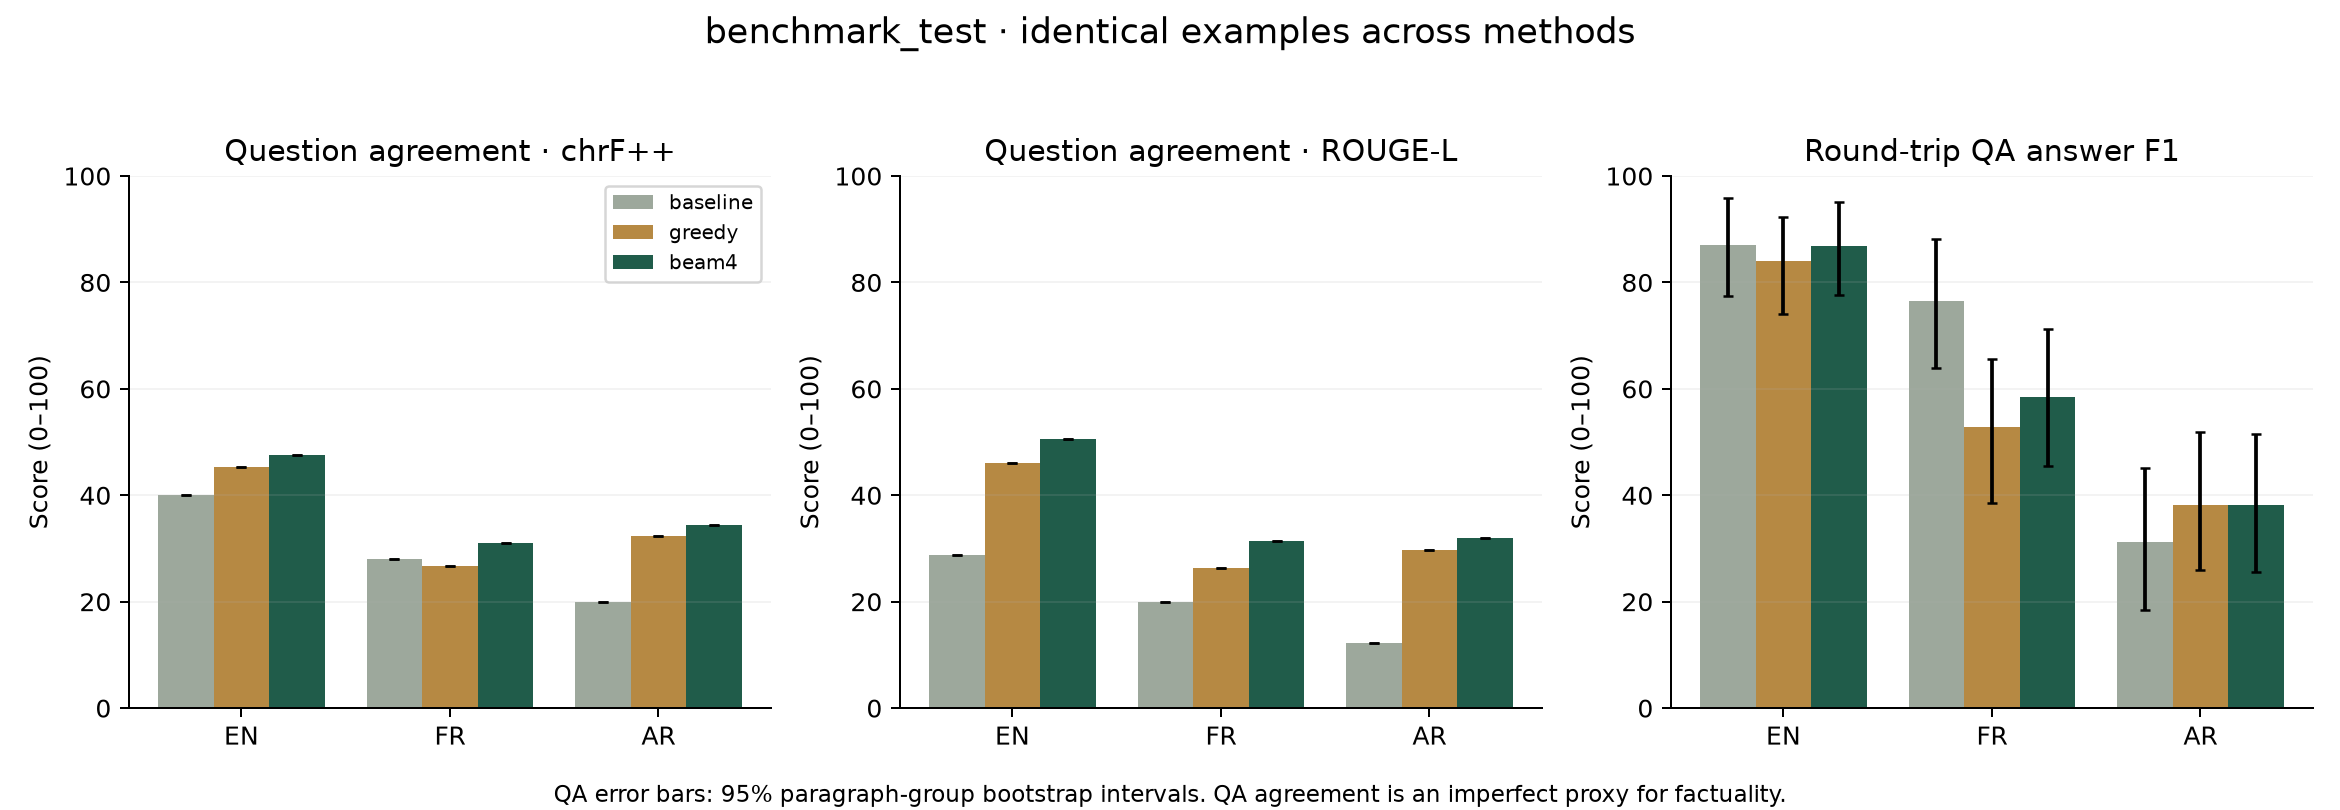

novel_test


,language,method,n,chrf_pp,rouge_l,answer_f1,accepted,errors
0,ar,baseline,24,40.313178,33.817522,95.833333,95.833333,0
1,ar,beam4,24,47.418116,44.431670,66.203704,70.833333,0
2,ar,greedy,24,43.238891,40.441240,58.333333,58.333333,0
3,ar,reference_control,24,100.000000,100.000000,83.333333,83.333333,0
4,ar,unrelated_control,24,12.241691,7.280821,0.000000,0.000000,0
5,en,baseline,24,52.796270,47.812858,75.000000,75.000000,0
6,en,beam4,24,61.827576,63.757856,71.527778,75.000000,0
7,en,greedy,24,58.679420,59.421666,70.138889,75.000000,0
8,en,reference_control,24,100.000000,100.000000,77.777778,79.166667,0
9,en,unrelated_control,24,20.335006,24.310141,0.000000,0.000000,0


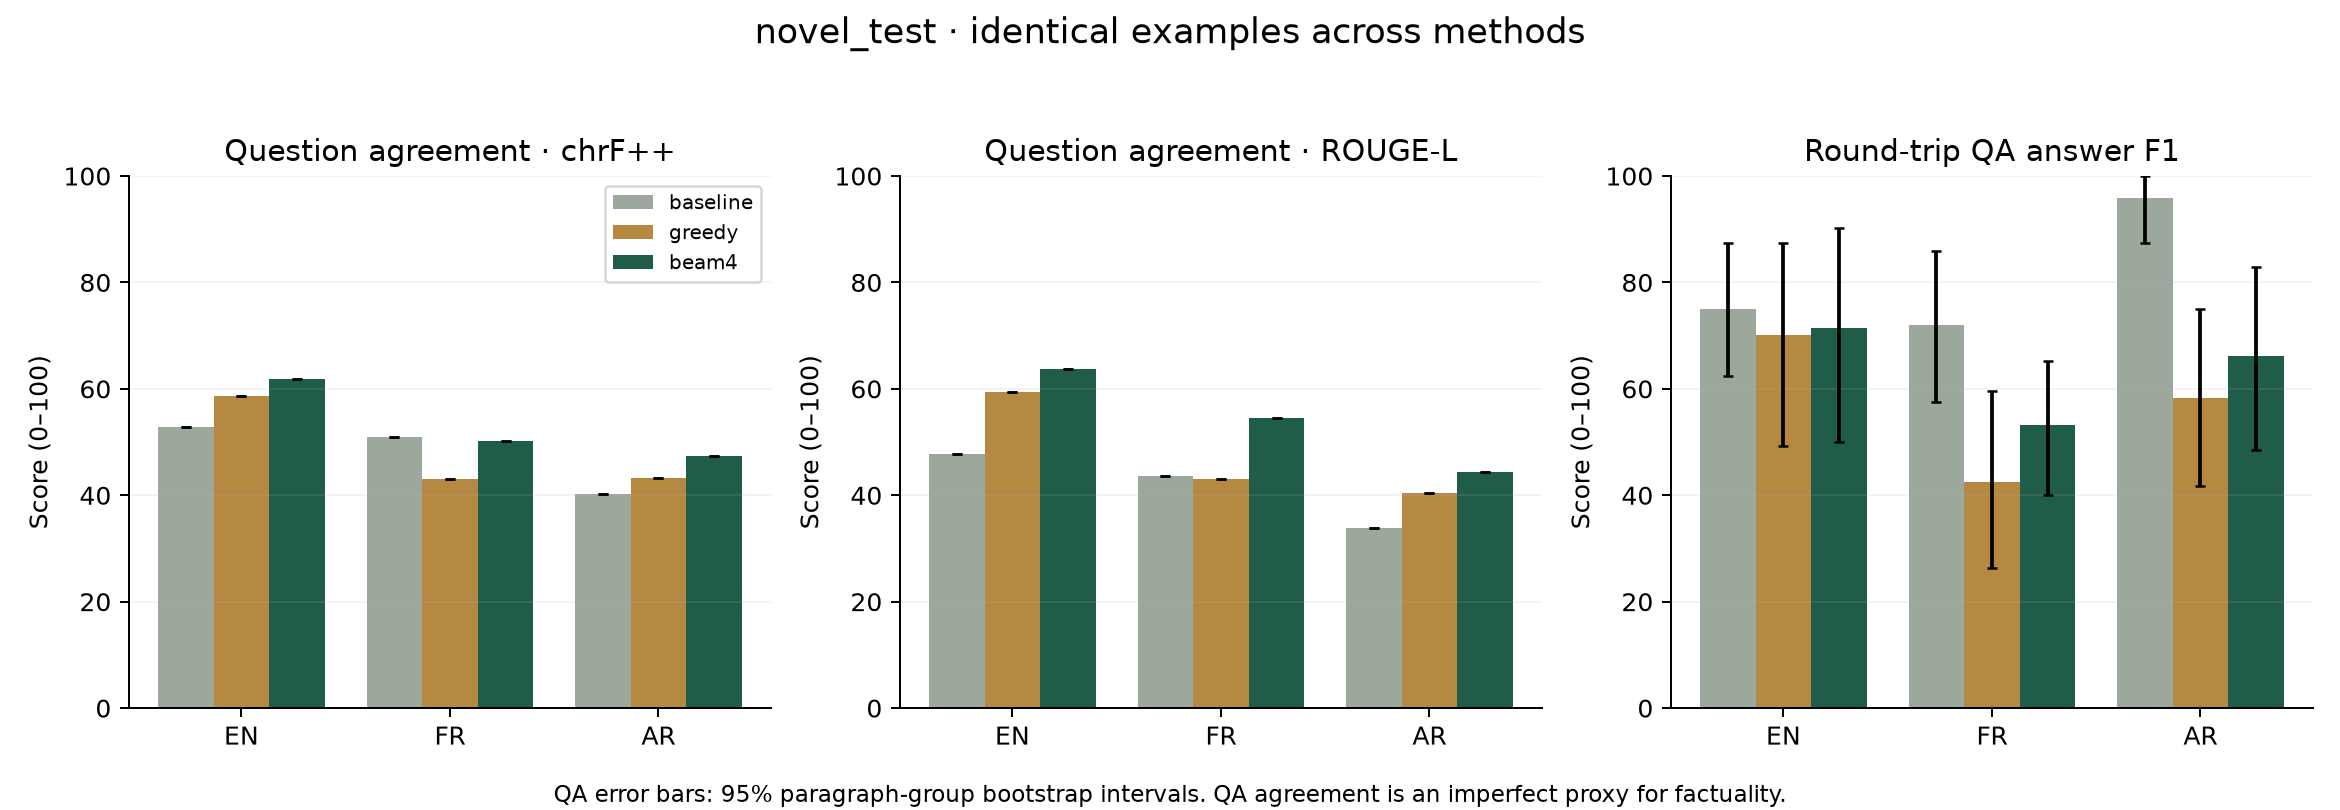

lora_test


,language,method,n,chrf_pp,rouge_l,answer_f1,accepted,errors
0,en,baseline,40,40.003485,28.690710,87.059524,87.5,0
1,en,beam4,40,47.552764,50.581710,86.871352,90.0,0
2,en,lora_beam4,40,48.066010,51.124497,89.371352,92.5,0
3,en,reference_control,40,100.000000,100.000000,85.328559,87.5,0
4,en,unrelated_control,40,15.065157,16.396208,0.000000,0.0,0


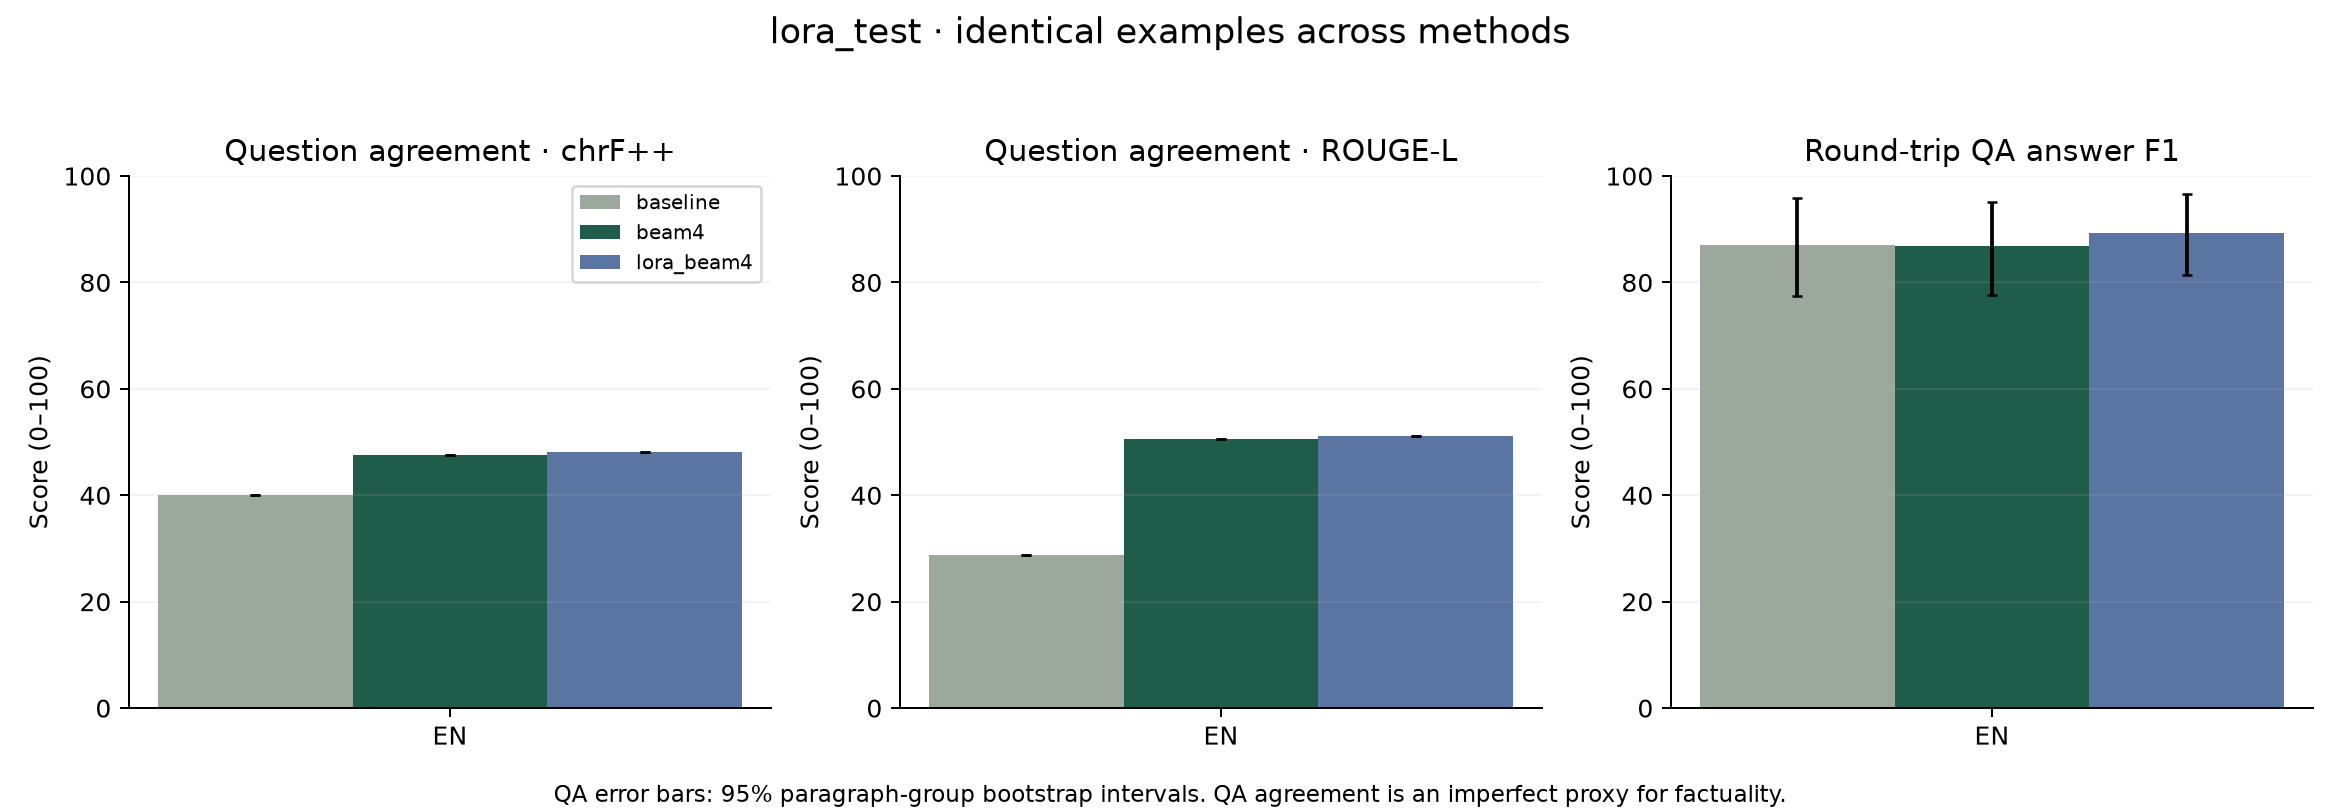

lora_novel_test


,language,method,n,chrf_pp,rouge_l,answer_f1,accepted,errors
0,en,baseline,24,52.796270,47.812858,75.000000,75.000000,0
1,en,beam4,24,61.827576,63.757856,71.527778,75.000000,0
2,en,lora_beam4,24,62.357490,64.465591,71.527778,75.000000,0
3,en,reference_control,24,100.000000,100.000000,77.777778,79.166667,0
4,en,unrelated_control,24,20.335006,24.310141,0.000000,0.000000,0


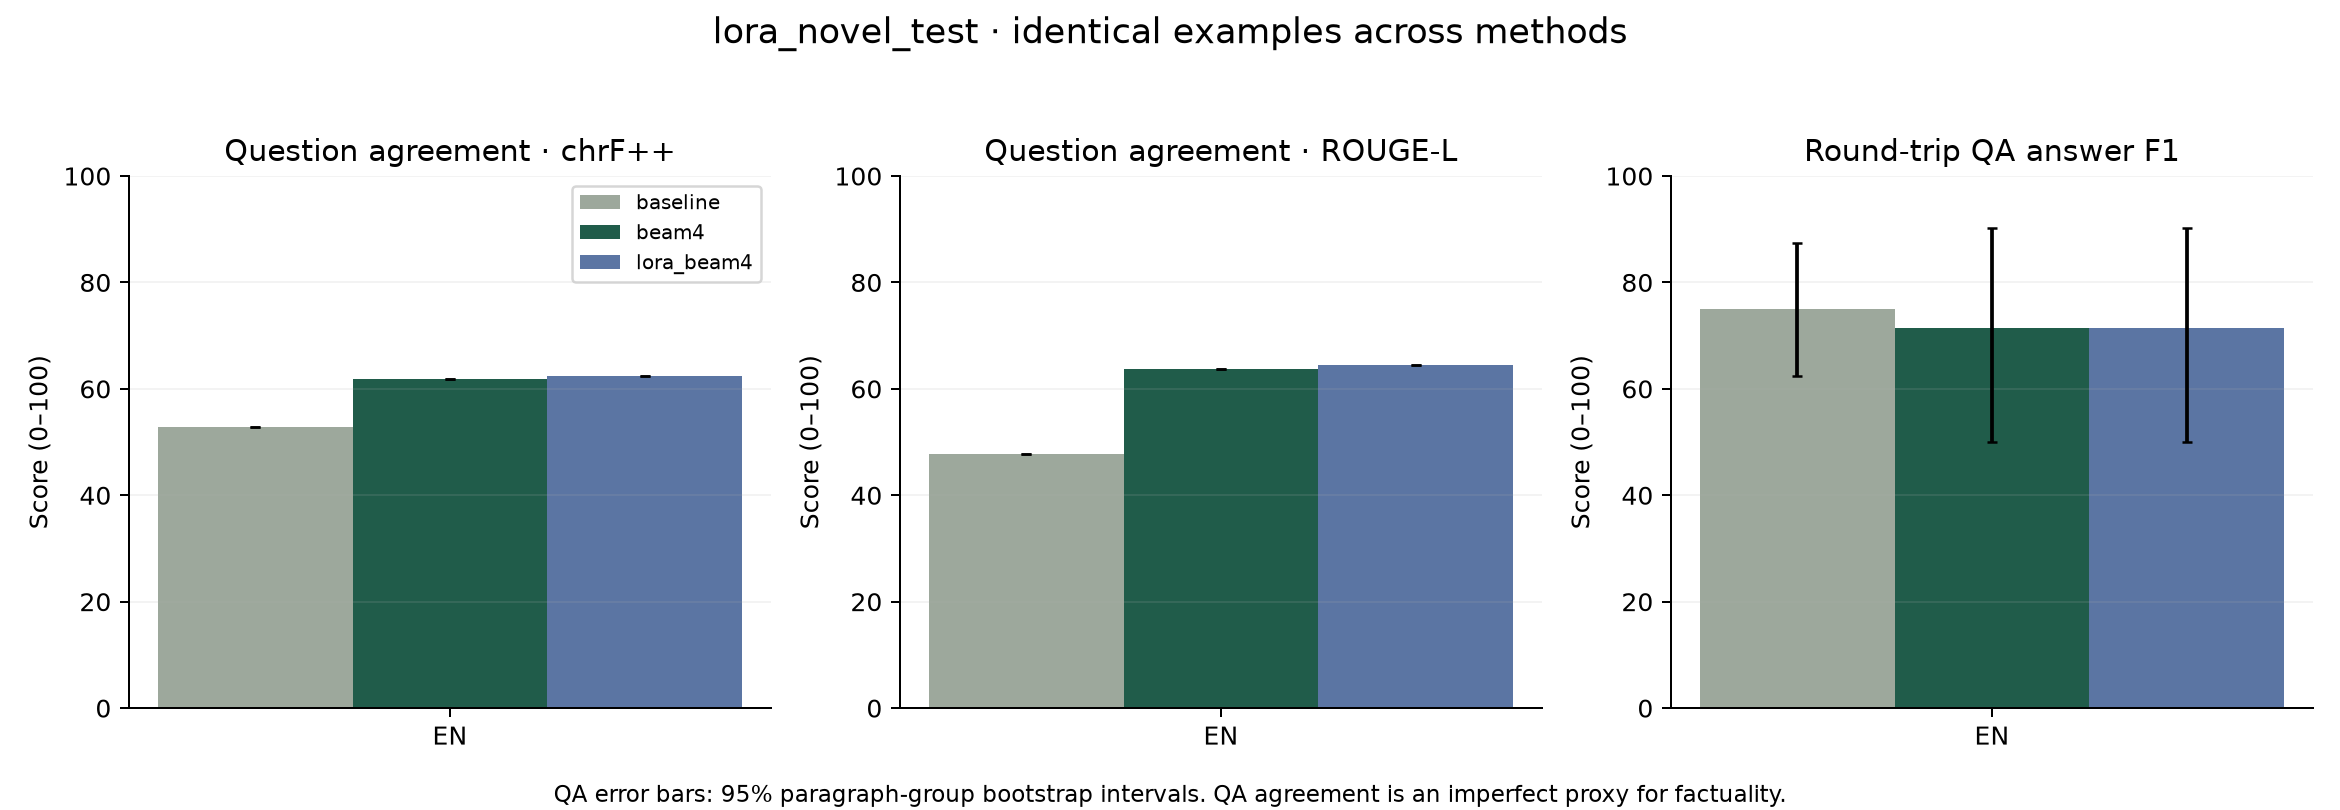

In [5]:
for name in ['benchmark_test', 'novel_test', 'lora_test', 'lora_novel_test']:
    summary = ROOT / 'results' / name / 'summary.csv'
    if summary.exists():
        print(name)
        table = pd.read_csv(summary)
        display(table[[c for c in ['language','method','n','chrf_pp','rouge_l','answer_f1','accepted','errors'] if c in table]])
        figure = summary.parent / 'comparison.png'
        if figure.exists():
            display(Image(filename=str(figure), width=950))


## 5. Small training extension and error analysis

`scripts/train_lora.py` freezes the English T5 backbone and trains rank-8 updates to
attention Q/V projections using only the training partition. It selects the adapter by
development cross-entropy and records seeds, counts, hashes, trainable parameters,
losses and runtime. A lower token loss does not guarantee better generated questions.

Use `results/*/human_review.csv` to annotate relevance, answerability and fluency (0–2),
with error categories such as answer leakage, wrong relation, grammar, wrong language
or judge failure. Blank ratings are pending human review, not measured human scores.


In [6]:
training = ROOT / 'artifacts/english_lora/training_manifest.json'
if training.exists():
    info = json.loads(training.read_text(encoding='utf-8'))
    display({key: info[key] for key in ['trainable_parameters', 'total_parameters', 'steps',
                                       'initial_dev_loss', 'best_dev_loss', 'best_step', 'elapsed_seconds']})
review = ROOT / 'results/benchmark_test/review_examples.json'
if review.exists():
    examples_to_review = json.loads(review.read_text(encoding='utf-8'))
    display(pd.DataFrame(examples_to_review)[['selection', 'language', 'method', 'question', 'answer', 'qa_answer', 'answer_f1']])


{'trainable_parameters': 294912,
 'total_parameters': 60787712,
 'steps': 40,
 'initial_dev_loss': 1.594350790155345,
 'best_dev_loss': 1.5834094843840951,
 'best_step': 40,
 'elapsed_seconds': 64.17055290000008}

,selection,language,method,question,answer,qa_answer,answer_f1
0,lowest QA agreement,ar,baseline,"حرب أكتوبر ""حرب العاشر من رمضان"" كما تعرف في م...",حرب يوم الغفران,,0.0
1,lowest QA agreement,ar,baseline,سليمان خان الأول بن سليم خان الأول (بالتركية ا...,Sultan Süleyman-ı Evvel),,0.0
2,lowest QA agreement,ar,baseline,استقل السودان عن بريطانيا و مصر في ما واشتعلت ...,الأول من يناير 1956,,0.0
3,highest QA agreement,fr,baseline,"Comme l'illustrent nos confrères, si Orange ve...",909 €,"909 €,",1.0
4,highest QA agreement,fr,baseline,L'interface de cet égaliseur est particulièrem...,conservés même lorsqu'on les connecte à un aut...,conservés même lorsqu'on les connecte à un aut...,1.0
5,highest QA agreement,fr,baseline,"«C'est le plus difficile selon les experts», c...",retrouver l'élément déclencheur,"«retrouver l'élément déclencheur»,",1.0
6,lowest QA agreement,ar,greedy,من هو السلطان العثماني الأول؟,Sultan Süleyman-ı Evvel),,0.0
7,lowest QA agreement,ar,greedy,ما هي أكبر دولة في المملكة المتحدة؟,England,,0.0
8,lowest QA agreement,ar,greedy,ما هي بعض الأمثلة على أمثلة لتفسير التفسير؟,انفجار عظيم، وأن أدنى نقطة على سطح الأرض هي ال...,,0.0
9,highest QA agreement,fr,greedy,Comment se traduit le partage de son lit avec ...,un malheureux manque de jugement,un malheureux manque de jugement,1.0


## 6. Inspect factual failures and stress the verifier

`results/qualitative_examples.json` contains source-linked qualitative inspections,
not blinded human ratings. Cases include a question that wrongly merges David and
Trajan's Column despite perfect QA agreement, and an Arabic question identical to its
reference for which the verifier selects the wrong answer.

The Arabic solar-panel question asks who **invented** the lamp, although its passage
only describes connecting a panel to a lamp. Its perfect QA agreement is a false
positive. An earlier explanatory annotation incorrectly called it a supported
connection question; the annotation is corrected without changing predictions or scores.

An **exploratory post-hoc** probe appends an unsupported 'on Mars' qualifier to original
classroom questions. It measures whether the fixed review rules can miss unsupported
premises. It does not tune the generators or thresholds and does not estimate the
frequency of such errors in naturally generated questions.


Automated qualitative inspection; human verification pending


,language,category,question,answer,qa_answer,review
0,en,Purpose confused with method,How do the Trio Tribe map their ancestral lands?,to help strengthen their territorial claims,handheld GPS devices and programs like Google ...,The intended answer explains why the tribe map...
1,en,Ambiguous time relation,In what year did Chivas USA play at the StubHu...,2014,,The passage says the club played from 2005 to ...
2,en,Unsupported relation; verifier false positive,What is the name of Michelangelo's replica of ...,David,David.,The passage describes Trajan's Column in one c...
3,en,Date/quantity error missed by QA,"In how many, the Democratic Republic of Afghan...",1992,"1992,",The numeric template substitutes 'how many' fo...
4,fr,Wrong semantic role,Qui a été attaqué ?,Ankara,pro-Haftar,"The target is Ankara, which provided military ..."
5,fr,Generic question loses intended focus,Quelle est la conséquence de la recherche ?,manquer de temps,,The target 'manquer de temps' explains the nar...
6,ar,Verifier false negative on an identical reference,من هو والد جندح؟,حُجر,كندة.,The generated Arabic question is exactly the r...
7,ar,Question type and answer-language mismatch,من هو السلطان سليمان خان الأول؟,Sultan Süleyman-ı Evvel),سليم خان الأول,The intended answer is Suleyman's Turkish writ...
8,ar,Morphological answer leakage and relation error,ما هو مقياس الأمطار الذي تم قياسه على سطح المد...,مقياس المطر,المطر,The source says a rain gauge measured rainfall...
9,en,Supported classroom question,Who connected a small solar panel to a lamp?,Rami,Rami,The generated question asks who connected the ...


,language,condition,n,target_answer_f1,automatic_acceptance_pct
0,en,reference,24,77.777778,79.166667
1,en,unsupported_qualifier,24,4.166667,4.166667
2,fr,reference,24,73.849206,75.000000
3,fr,unsupported_qualifier,24,42.738095,41.666667
4,ar,reference,24,83.333333,83.333333
5,ar,unsupported_qualifier,24,48.611111,50.000000


lora_test {'n': 40, 'mean_answer_f1_change_pp': 2.5, 'paired_group_bootstrap_ci95_pp': [0.0, 7.5], 'improved_examples': 1, 'worsened_examples': 0, 'unchanged_examples': 39, 'interpretation': 'Small paired subset. Intervals include sampling variation only; no test-based model selection.'}
lora_novel_test {'n': 24, 'mean_answer_f1_change_pp': 0.0, 'paired_group_bootstrap_ci95_pp': [0.0, 0.0], 'improved_examples': 0, 'worsened_examples': 0, 'unchanged_examples': 24, 'interpretation': 'Small paired subset. Intervals include sampling variation only; no test-based model selection.'}


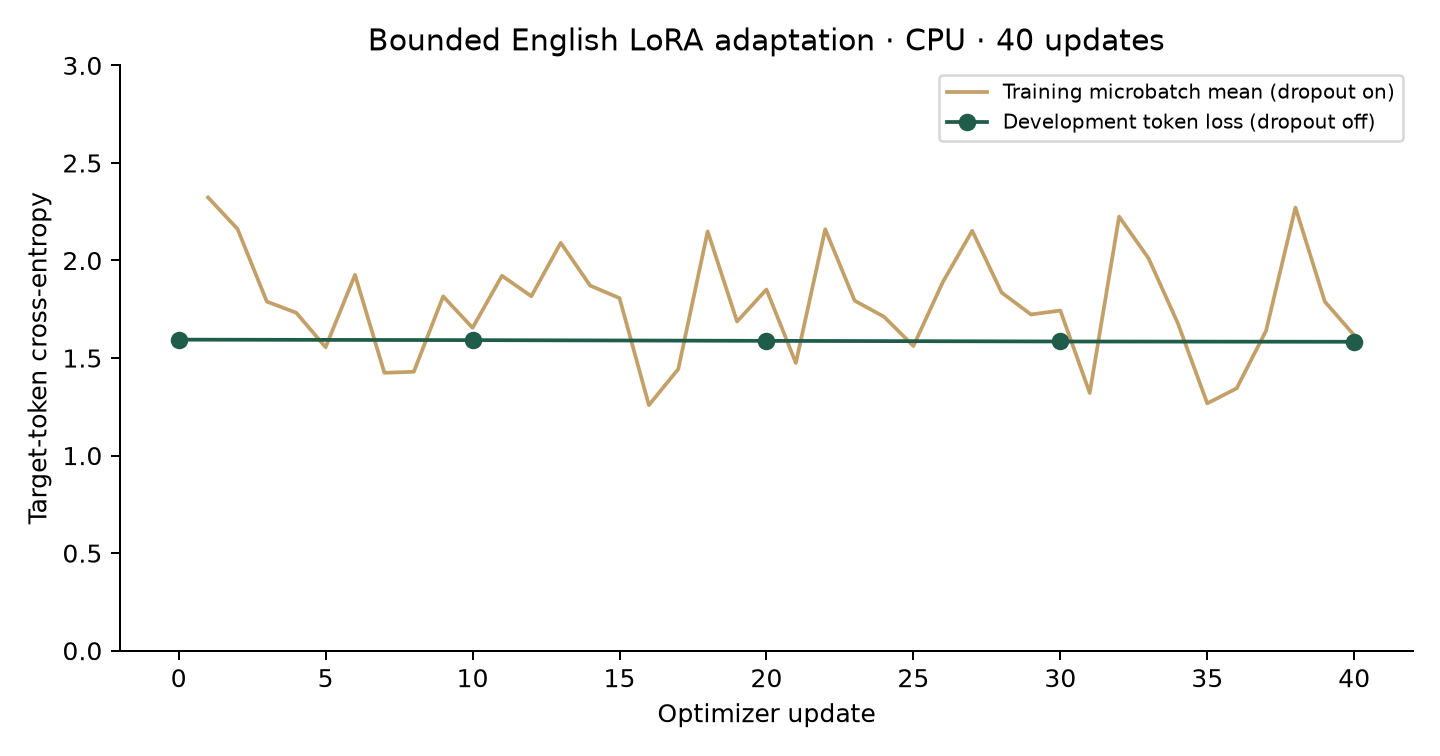

In [7]:
qualitative = ROOT / 'results/qualitative_examples.json'
if qualitative.exists():
    inspected = json.loads(qualitative.read_text(encoding='utf-8'))
    print(inspected['reviewer'])
    display(pd.DataFrame(inspected['examples'])[['language','category','question','answer','qa_answer','review']])
stress = ROOT / 'results/verifier_stress/summary.json'
if stress.exists():
    display(pd.DataFrame(json.loads(stress.read_text(encoding='utf-8'))))
for name in ['lora_test', 'lora_novel_test']:
    paired = ROOT / 'results' / name / 'adaptation_delta.json'
    if paired.exists():
        print(name, json.loads(paired.read_text(encoding='utf-8')))
loss_plot = ROOT / 'results/data/lora_loss_curve.png'
if loss_plot.exists():
    display(Image(filename=str(loss_plot), width=700))


## 7. Check robustness beyond a single result

Follow-up protocols are in `docs/EXTENSION_PROTOCOL.md`. Three seeds repeat 160-update
English LoRA training; report every run and distinguish seed variation from topic bootstrap
uncertainty. A separate English run excludes training articles shared with development/test.
The verifier study contrasts two QA judges on reference questions and three constructed
negative conditions. These controls do not replace human judgments of generated quality.
The blinded booklet contains 54 items; annotation remains pending until people supply CSVs.


,seed,dataset,n_unique_inputs,selected_for_optional_app_by_dev_loss,best_dev_loss,best_step,unadapted_qa_f1,adapted_qa_f1,qa_f1_delta_pp,paired_topic_ci95_pp,unadapted_rouge_l,adapted_rouge_l,qa_f1_improved_inputs,qa_f1_worsened_inputs
0,13,public,40,False,1.526257,140,86.871352,89.635281,2.763930,"[0.0, 8.027859237536656]",50.581710,49.890232,2,0
1,42,public,40,True,1.524232,160,86.871352,89.635281,2.763930,"[0.0, 8.027859237536656]",50.581710,49.841815,2,0
2,73,public,40,False,1.527054,160,86.871352,88.726190,1.854839,"[-5.64516129032258, 9.919354838709676]",50.581710,48.253311,2,1
3,13,classroom,24,False,1.526257,140,71.527778,74.305556,2.777778,"[-4.166666666666667, 12.5]",63.757856,64.156373,1,1
4,42,classroom,24,True,1.524232,160,71.527778,76.388889,4.861111,"[-2.777777777777778, 15.277777777777777]",63.757856,63.063173,2,1
5,73,classroom,24,False,1.527054,160,71.527778,68.750000,-2.777778,"[-6.9444444444444455, 0.0]",63.757856,63.418822,0,2


,dataset,unique_test_inputs,training_seeds,mean_qa_f1_delta_pp,between_seed_sample_sd_pp,topic_bootstrap_ci95_of_seed_mean_pp,interpretation
0,public,40,3,2.460899,0.524864,"[-1.6676441837732159, 8.294232649071358]",Topic bootstrap holds the three trained seeds ...
1,classroom,24,3,1.620370,3.948778,"[-3.703703703703704, 9.027777777777777]",Topic bootstrap holds the three trained seeds ...


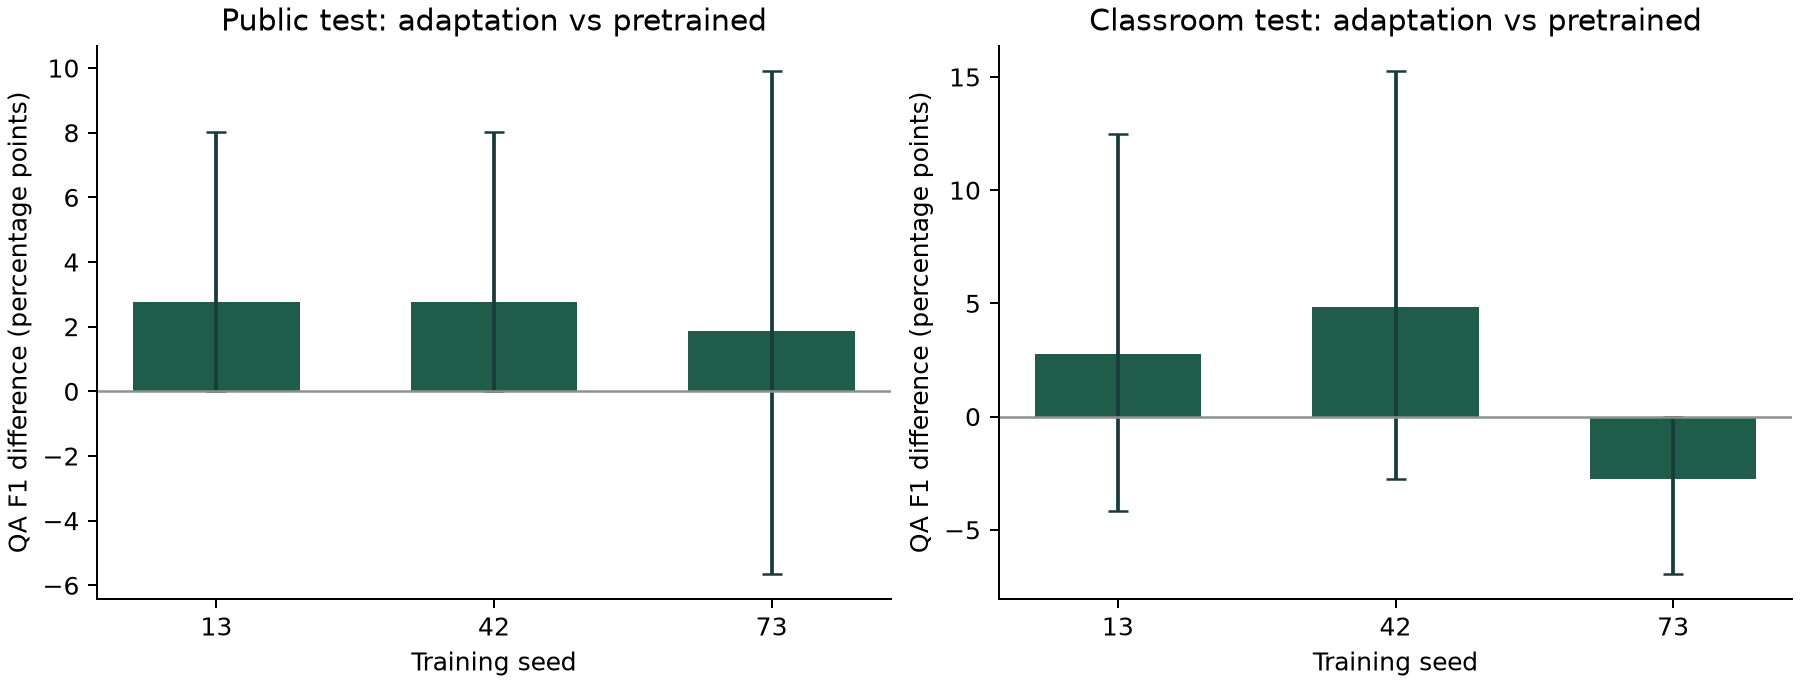

,partition,language,verifier,reference_f1,reference_em,reference_acceptance_pct,negative_false_acceptance_pct,constructed_control_balanced_accuracy_pct,errors
0,test,en,original,77.777778,75.000000,79.166667,1.388889,88.888889,0
1,test,en,multilingual,98.611111,95.833333,100.000000,33.333333,83.333333,0
2,test,fr,original,73.849206,62.500000,75.000000,13.888889,80.555556,0
3,test,fr,multilingual,91.307720,62.500000,100.000000,33.333333,83.333333,0
4,test,ar,original,83.333333,83.333333,83.333333,18.055556,82.638889,0
5,test,ar,multilingual,86.111111,75.000000,91.666667,31.944444,79.861111,0


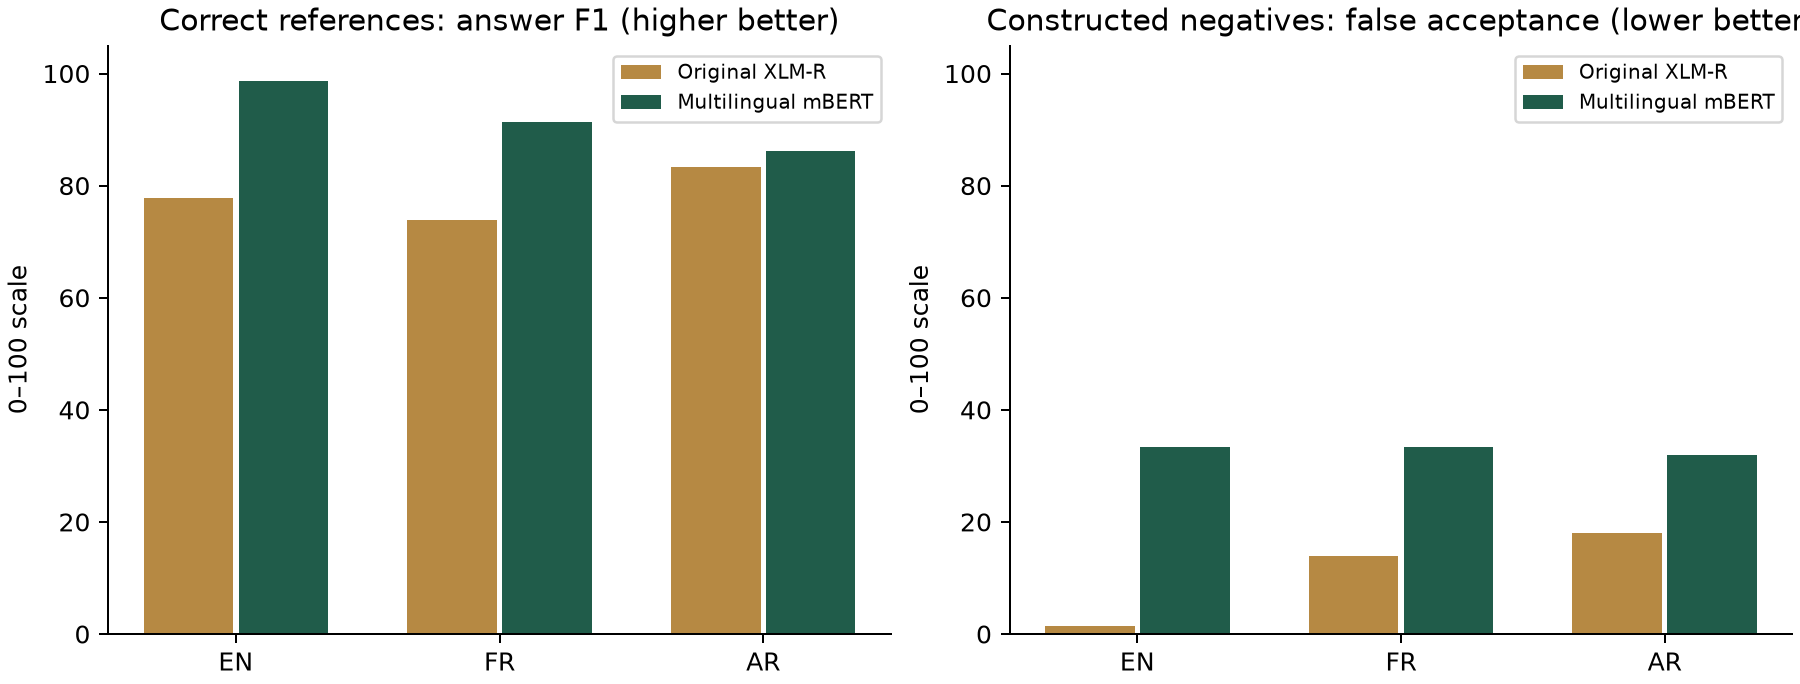

,language,held_out_partition,n_training,n_held_out,exact_paragraph_overlaps,near_duplicate_candidates_cosine_ge_0_90,maximum_char_ngram_cosine,held_out_rows_with_title,held_out_rows_sharing_training_article_title
0,en,dev,600,15,0,0,0.601606,15,11
1,en,test,600,40,0,0,0.308502,40,0
2,fr,dev,280,15,0,0,0.208093,0,0
3,fr,test,280,40,0,0,0.267290,0,0
4,ar,dev,193,15,0,1,0.913070,15,13
5,ar,test,193,40,0,0,0.824042,40,4


Human evaluation: pending_human_annotation


In [8]:
seed_path = ROOT / 'results/seed_study/summary.json'
if seed_path.exists():
    seed_study = json.loads(seed_path.read_text(encoding='utf-8'))
    display(pd.DataFrame(seed_study['runs']))
    display(pd.DataFrame(seed_study['paired_seed_means']))
    display(Image(filename=str(seed_path.parent / 'seed_stability.png'), width=900))
verifier_path = ROOT / 'results/verification_study/summary.json'
if verifier_path.exists():
    verifier_study = json.loads(verifier_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([{k:v for k,v in row.items() if k != 'conditions'}
                          for row in verifier_study['models'] if row['partition'] == 'test']))
    display(Image(filename=str(verifier_path.parent / 'comparison.png'), width=900))
audit_path = ROOT / 'results/data/overlap_audit.json'
if audit_path.exists():
    audit = json.loads(audit_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([{k:v for k,v in row.items() if k != 'closest_pairs'} for row in audit['results']]))
human_path = ROOT / 'results/human_evaluation/summary.json'
if human_path.exists():
    print('Human evaluation:', json.loads(human_path.read_text(encoding='utf-8'))['status'])


## 8. Train native adapters on larger human datasets

The expanded study uses SQuAD, NewsQuAD-fr and ARCD plus native Arabic TyDiQA-GoldP.
It reserves published evaluation sources and uses larger development sets. Training rows
seen by a selected checkpoint can be fewer than rows seen by the entire early-stopped run.
Arabic targets retain the checkpoint's native `question:` prefix during training; display
generation removes it. Checkpoint/app selection uses development loss, not test scores.
The original and expanded blind-review booklets remain pending genuine human annotation.


,language,training_examples,development_examples,steps,best_step,unique_training_ids_seen,saved_checkpoint_unique_examples_seen,initial_dev_loss,best_dev_loss
0,en,5000,200,600,350,4800,2800,1.422125,1.336441
1,fr,1000,60,256,224,1000,1000,2.058667,1.927281
2,ar,1990,150,512,512,1990,1990,3.267312,1.242665


,language,dataset,n_unique_inputs,independent_groups,base_qa_f1,adapted_qa_f1,qa_f1_delta_pp,paired_topic_ci95_pp,base_rouge_l,adapted_rouge_l,...,adapted_chrf_pp,base_answer_leak_pct,adapted_answer_leak_pct,base_automatic_acceptance_pct,adapted_automatic_acceptance_pct,improved_inputs,worsened_inputs,previous_adapter_qa_f1,expanded_minus_previous_qa_f1_pp,expanded_minus_previous_ci95_pp
0,en,public,40,40,86.871352,89.371352,2.500000,"[0.0, 7.5]",50.581710,50.088880,...,46.802356,0.000000,0.000000,90.000000,92.500000,1,0,89.635281,-0.263930,"[-0.7917888563049854, 0.0]"
1,en,classroom,24,12,71.527778,73.611111,2.083333,"[0.0, 6.25]",63.757856,62.232009,...,62.585785,4.166667,4.166667,75.000000,75.000000,1,0,76.388889,-2.777778,"[-12.5, 4.166666666666667]"
2,fr,public,40,40,58.375000,51.123016,-7.251984,"[-17.749255952380956, 2.708333333333333]",31.330688,28.766105,...,28.215075,0.000000,0.000000,62.500000,52.500000,2,6,NaN,NaN,NaN
3,fr,classroom,24,12,53.272283,61.466728,8.194444,"[-1.388888888888889, 19.86111111111111]",54.487463,51.169107,...,44.667586,0.000000,0.000000,54.166667,66.666667,3,1,NaN,NaN,NaN
4,ar,public,40,40,38.246703,39.514641,1.267938,"[-3.4939668174962293, 6.21492673992674]",31.907981,31.459256,...,34.493567,0.000000,0.000000,40.000000,40.000000,4,1,NaN,NaN,NaN
5,ar,classroom,24,12,66.203704,64.814815,-1.388889,"[-11.145833333333329, 5.555555555555558]",44.431670,45.431287,...,47.115377,0.000000,0.000000,70.833333,66.666667,2,2,NaN,NaN,NaN


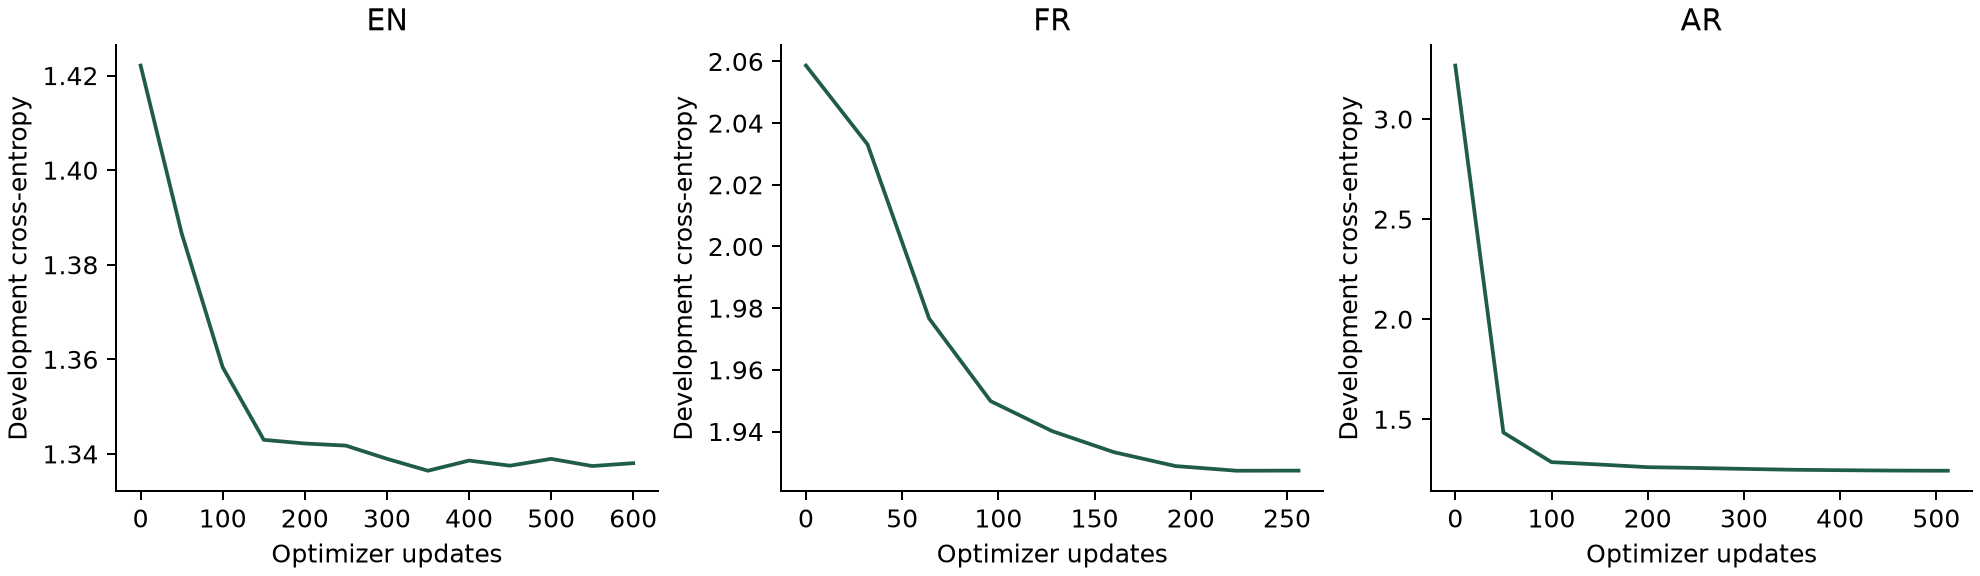

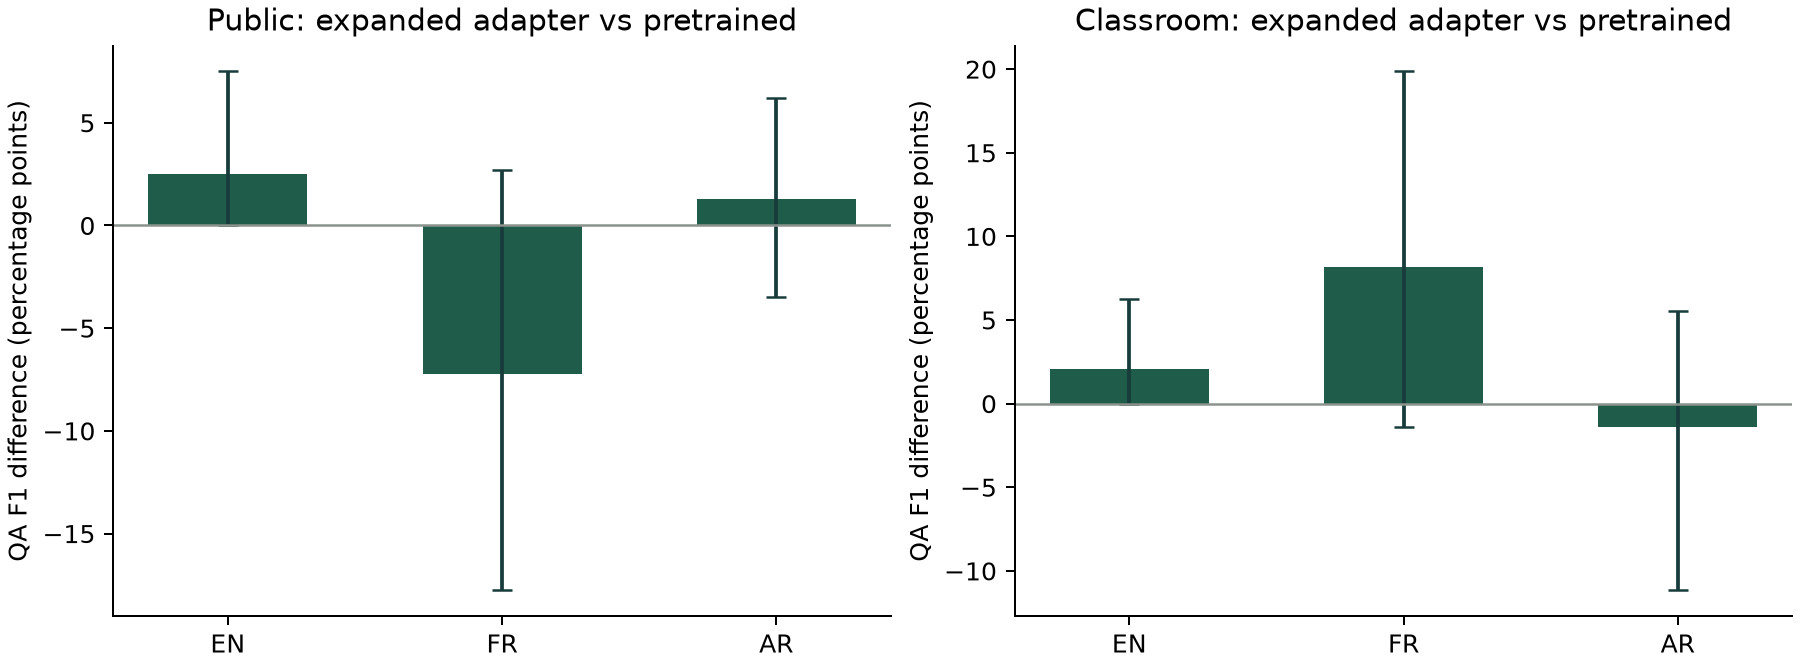

App adapter selection: {'en': 'artifacts/expanded/en', 'fr': 'artifacts/expanded/fr', 'ar': 'artifacts/expanded/ar'}
Results are follow-up measurements on previously inspected tests; QA F1 is a proxy, not human question accuracy.
Revisit every prior beam-4 qualitative case. Original labels describe the OLD question only; no new human labels or prevalence estimates are claimed.


,language,original_case_category,before_question,after_question,before_answer_f1,after_answer_f1
0,en,Purpose confused with method,How do the Trio Tribe map their ancestral lands?,Why do tribal tribes map their ancestral lands?,0.000000,1.0
1,en,Ambiguous time relation,In what year did Chivas USA play at the StubHu...,In what year did the LA Galaxy and Chivas USA ...,0.000000,0.0
2,en,Unsupported relation; verifier false positive,What is the name of Michelangelo's replica of ...,What is the name of Michelangelo's replica of ...,1.000000,1.0
3,fr,Wrong semantic role,Qui a été attaqué ?,Qui est à l'origine de cette offensive ?,0.000000,1.0
4,fr,Generic question loses intended focus,Quelle est la conséquence de la recherche ?,Quelle est la conséquence de l'étude ?,0.000000,0.0
5,ar,Verifier false negative on an identical reference,من هو والد جندح؟,من هو أول شاعر عربي؟,0.000000,0.0
6,ar,Question type and answer-language mismatch,من هو السلطان سليمان خان الأول؟,من هو السلطان العثماني الأول؟,0.000000,0.0
7,ar,Morphological answer leakage and relation error,ما هو مقياس الأمطار الذي تم قياسه على سطح المد...,كيف تم قياس كمية الأمطار خلال الأسبوع؟,0.666667,1.0
8,en,Supported classroom question,Who connected a small solar panel to a lamp?,Who connected a small solar panel to a lamp?,1.000000,1.0
9,ar,Unsupported invention claim; verifier false po...,من الذي قام بإختراع المصباح؟,من الذي قام بإختراع المصباح؟,1.000000,1.0


,language,question,answer,adapter
0,en,Who planted twelve bean seeds in a tray?,Lina,artifacts/expanded/en
1,fr,Qui a planté trois graines de haricot ?,Lina,artifacts/expanded/fr
2,ar,من الذي زرع الفاصوليا في وعاء؟,لينا,artifacts/expanded/ar


In [9]:
expanded_path = ROOT / 'results/expanded_training/summary.json'
if expanded_path.exists():
    expanded = json.loads(expanded_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([{'language': lang,
                          **{key: info[key] for key in ['training_examples','development_examples','steps','best_step',
                             'unique_training_ids_seen','saved_checkpoint_unique_examples_seen','initial_dev_loss','best_dev_loss']}}
                         for lang, info in expanded['languages'].items()]))
    display(pd.DataFrame(expanded['evaluations']))
    display(Image(filename=str(expanded_path.parent / 'development_loss.png'), width=1000))
    display(Image(filename=str(expanded_path.parent / 'comparison.png'), width=900))
    print('App adapter selection:', {lang: info['selected_app_adapter'] for lang, info in expanded['languages'].items()})
    print('Results are follow-up measurements on previously inspected tests; QA F1 is a proxy, not human question accuracy.')
    paired_cases = ROOT / 'results/expanded_training/before_after_cases.json'
    if paired_cases.exists():
        cases = json.loads(paired_cases.read_text(encoding='utf-8'))
        print(cases['scope'])
        display(pd.DataFrame(cases['cases'])[['language','original_case_category','before_question','after_question',
                                             'before_answer_f1','after_answer_f1']])
    trained_examples = []
    if RUN_NEURAL:
        for row in examples:
            selected = expanded['languages'][row['language']]['selected_app_adapter']
            result = generate_question(row['context'], row['answer'], row['language'],
                                       answer_start=row['answer_start'], beams=4, checkpoint=selected)
            trained_examples.append({'language': row['language'], 'question': result.question,
                                     'answer': row['answer'], 'adapter': selected or 'unadapted'})
        display(pd.DataFrame(trained_examples))
else:
    print('Expanded training is not complete; no additional results are claimed.')


## 9. Demonstrate and explain

Launch `python -m streamlit run app.py`. Choose a language, paste a passage, supply exact
answers or use TF-IDF suggestions, and inspect the questions and evidence. Export a
student worksheet, answer key, CSV, JSON or Moodle XML.

See `docs/DEFENSE_GUIDE.md` for course connections and technical Q&A. No external paid API is used.
